# Closure test of the point-source folding with background

In an unbinned fit with a dominant background, any mismatch between the integral of the
source density over the selected data space and the expected counts `S`,
`c = (int s dx) / S`, biases the flux by `dK/K ~ (c - 1) B_eff / S`, about 10 times `c - 1`
for the Crab in 3 h. Signal-only fits are immune (`K = N / S`).

This notebook generates Crab events from the IRF itself (`simulate_point_source_events`,
real `hist_simple` response and attitude, 3 h) plus an ideal background with a known density
(`IsotropicPowerLawBackground`), and fits them with the broadened Trapz folding and that
background model. Since the events come from the same IRF, any bias comes from the folding.

- `c` is measured with the background events as importance samples: their density is known
  exactly, so `c = mean(s / b_norm) / S` over them, with `b_norm` the normalized background
  density.
- The fits of 10 realizations, with and without the background, give the bias of the flux and
  index.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import astropy.units as u
from astropy.time import Time
from astromodels import Powerlaw, PointSource
from scipy.optimize import minimize

from cosipy.background_estimation.analytic_background import IsotropicPowerLawBackground
from cosipy.data_io.EmCDSUnbinnedData import TimeTagEmCDSEventDataInSCFrameFromArrays
from cosipy.event_selection.energy_selection import EnergySelector
from cosipy.response.broadened_irf_cache import BroadenedIRFCache
from cosipy.response.relative_irf_hist import IRFRelativeHistUnpolarized
from cosipy.source_injector.point_source_events import simulate_point_source_events
from cosipy.spacecraftfile import SpacecraftHistory
from cosipy.threeml.psr_fixed_ei import UnbinnedThreeMLPointSourceResponseTrapz

# threeML (imported by cosipy) sets a non-interactive backend without a display
%matplotlib inline


WARNING TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html



In [2]:
data_path = Path('/home/user/dc4data')
irf_file = data_path / 'ResponseContinuum.area.relative.nonsparse_smoothing1p0.h5'

erange = (200., 5000.)
selection = EnergySelector(erange * u.keV)
tstart, tstop = Time('2028-03-23 10:36:00'), Time('2028-03-23 13:36:00')
sc = SpacecraftHistory.open(data_path / 'DC4_final_530km_3_month_with_slew_15sbins_GalacticEarth_SAA.fits')
sc = sc.select_interval(tstart, tstop)

K_true, index_true, piv = 2.5e-6, -2.2, 1000.
spectrum = Powerlaw(index=index_true, K=K_true, piv=piv)
spectrum.K.unit = 1 / u.cm ** 2 / u.s / u.keV
spectrum.piv.unit = u.keV
source = PointSource('Crab', l=184.56, b=-5.78, spectral_shape=spectrum)

bkg_rate, bkg_index = 12.29 * u.Hz, -2.  # about the DC4 rate in this window, after the cut
nreal = 10

irf = IRFRelativeHistUnpolarized.from_h5(irf_file, selections=selection)

## Realizations

Crab photons over 100 keV - 10 MeV, events from the IRF (conditional on the cut), plus the
background events.

In [3]:
t0 = time.time()
realizations = []
for r in range(nreal):
    rng = np.random.default_rng(r)
    crab, _ = simulate_point_source_events(irf, sc, source, energy_range_keV=(100., 10_000.), rng=rng)
    bkg = IsotropicPowerLawBackground.random_events(sc, bkg_rate, bkg_index, erange, rng)
    realizations.append((crab, bkg))
print(f'{time.time() - t0:.0f} s; per realization: {np.mean([c.nevents for c, _ in realizations]):.0f} Crab, '
      f'{np.mean([b.nevents for _, b in realizations]):.0f} background events')


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide




WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide




WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide




WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide




WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide



...


WARNING RuntimeWarning: invalid value encountered in divide




WARNING RuntimeWarning: invalid value encountered in divide




WARNING RuntimeWarning: invalid value encountered in divide




WARNING RuntimeWarning: invalid value encountered in divide



194 s; per realization: 1603 Crab, 119140 background events


All the events in one data set, so the folding (the expensive part, once per source
position) is computed once; each realization is fitted with its own events.

In [4]:
def concatenate(datasets):
    arrays = [np.concatenate([np.asarray(getattr(d, name), dtype=float) for d in datasets])
              for name in ('energy_keV', 'scattered_lon_rad_sc', 'scattered_lat_rad_sc', 'scattering_angle_rad')]
    t = Time(np.concatenate([d.time.utc.unix for d in datasets]), format='unix', scale='utc')
    return TimeTagEmCDSEventDataInSCFrameFromArrays(t.jd1, t.jd2, *arrays)


datasets = [d for pair in realizations for d in pair]
data = concatenate(datasets)
sizes = [d.nevents for d in datasets]
offsets = np.concatenate([[0], np.cumsum(sizes)])
crab_idx = [np.arange(offsets[2 * r], offsets[2 * r + 1]) for r in range(nreal)]
bkg_idx = [np.arange(offsets[2 * r + 1], offsets[2 * r + 2]) for r in range(nreal)]

cache = BroadenedIRFCache(IRFRelativeHistUnpolarized.from_h5(irf_file), energy_range_keV=(100., 10_000.))
cells = UnbinnedThreeMLPointSourceResponseTrapz.cells_for(source, cache, accuracy=1e-3)

t0 = time.time()
psr = UnbinnedThreeMLPointSourceResponseTrapz(data, irf, sc, cache, cells, offset=None)
psr.set_source(source)
psr.init_cache()
print(f'{len(cells)} cells; folding of {data.nevents} events: {time.time() - t0:.0f} s')

bkg_model = IsotropicPowerLawBackground(data, sc, bkg_rate, bkg_index, erange)
livetime = sc.cumulative_livetime().to_value(u.s)
b_norm = np.asarray(bkg_model.expectation_density()) / bkg_model.expected_counts()  # per event, integrates to 1


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide




WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide




WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide




WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide




WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide



...


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide




WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide




WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide




WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide



16 cells; folding of 1207423 events: 354 s


## c

`int s dx = E_b[s / b_norm]` over background events, for the true spectrum.

In [5]:
s = np.asarray(psr.expectation_density())
S = psr.expected_counts()
w = np.concatenate([s[i] / b_norm[i] for i in bkg_idx])
c, c_err = w.mean() / S, w.std() / np.sqrt(w.size) / S
print(f'S = {S:.1f}, c = {c:.4f} +- {c_err:.4f}')

S = 1595.3, c = 1.0002 +- 0.0030


## Fits

Unbinned likelihood `sum log(s_i + b_i) - S - B` over the events of each realization, with
free `K`, index and background rate (and `K`, index alone for the signal-only fits of the
Crab events).

In [6]:
def set_spectrum(log_k, index):
    spectrum.K.value = np.exp(log_k)
    spectrum.index.value = index


def fit(idx, with_background):
    def negloglike(x):
        set_spectrum(x[0], x[1])
        s = np.asarray(psr.expectation_density())[idx]
        S = psr.expected_counts()
        if with_background:
            rate = np.exp(x[2])
            return -(np.sum(np.log(s + rate * bkg_model._density_per_rate[idx])) - S - rate * livetime)
        return -(np.sum(np.log(s)) - S)

    x0 = [np.log(K_true), index_true] + ([np.log(bkg_rate.to_value(u.Hz))] if with_background else [])
    result = minimize(negloglike, x0, method='Nelder-Mead', options=dict(xatol=1e-5, fatol=1e-4, maxiter=4000))
    set_spectrum(np.log(K_true), index_true)
    return result.x


t0 = time.time()
with_bkg = np.array([fit(np.concatenate([crab_idx[r], bkg_idx[r]]), True) for r in range(nreal)])
signal_only = np.array([fit(crab_idx[r], False) for r in range(nreal)])
print(f'fits: {time.time() - t0:.0f} s')

for name, x in (('with background', with_bkg), ('signal only', signal_only)):
    k = np.exp(x[:, 0]) / K_true - 1
    idx = x[:, 1] - index_true
    print(f'{name:16s}  K/K_true - 1 = {k.mean():+.3f} +- {k.std(ddof=1) / np.sqrt(nreal):.3f}   '
          f'index - true = {idx.mean():+.3f} +- {idx.std(ddof=1) / np.sqrt(nreal):.3f}')
print(f'background rate / true - 1 = {(np.exp(with_bkg[:, 2]) / bkg_rate.to_value(u.Hz) - 1).mean():+.4f}')

fits: 17 s
with background   K/K_true - 1 = -0.052 +- 0.039   index - true = -0.072 +- 0.033
signal only       K/K_true - 1 = +0.009 +- 0.009   index - true = +0.007 +- 0.011
background rate / true - 1 = -0.0010


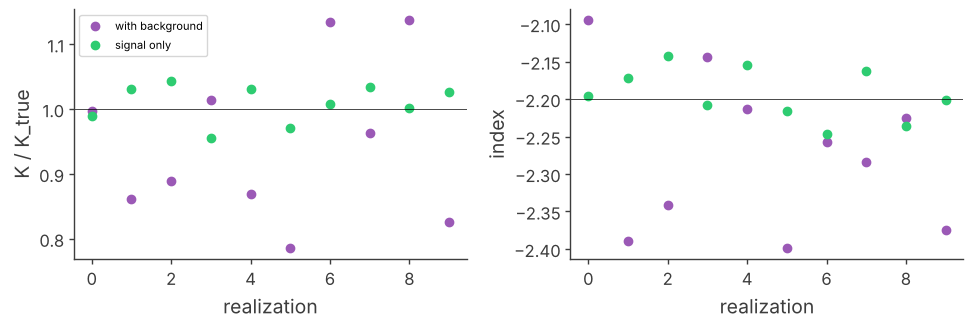

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, col, label, true in ((axs[0], 0, 'K / K_true', None), (axs[1], 1, 'index', index_true)):
    for x, name in ((with_bkg, 'with background'), (signal_only, 'signal only')):
        v = np.exp(x[:, 0]) / K_true if col == 0 else x[:, 1]
        ax.plot(np.arange(nreal), v, 'o', label=name)
    ax.axhline(1 if col == 0 else true, color='k', lw=0.5)
    ax.set_xlabel('realization')
    ax.set_ylabel(label)
axs[0].legend()
fig.tight_layout()

`c` is consistent with 1, so the background does not amplify any normalization error, and the
fitted flux and index with background agree with the injected ones within the scatter of the
realizations, like the signal-only fits. (Before the cleanup, the same test gave `c = 1.008`
and `K` +12% with the per-event Trapz nodes of #15.)